In [1]:

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


import re


import warnings
warnings.filterwarnings("ignore")


print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("Libraries imported successfully ✅")

Pandas: 3.0.5
NumPy: 2.5.2
Libraries imported successfully ✅


In [2]:


dataset_path = "dataset/complaints.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully ✅")

df.head()

Dataset loaded successfully ✅


,text,category
0,Please report: pothole near my house; causing ...,Pothole/Road Damage
1,"big pothole near my house, since last week; ca...",Pothole/Road Damage
2,Urgent: near my house road broken hai. causing...,Pothole/Road Damage
3,gaddha on road near my house. causing accident...,Pothole/Road Damage
4,"Need help, rasta kharab aahe near my house -- ...",Pothole/Road Damage


In [3]:


print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
print(df.columns)

print("\nDataset information:")
df.info()

Number of rows: 2100
Number of columns: 2

Columns:
Index(['text', 'category'], dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2100 entries, 0 to 2099
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      2100 non-null   str  
 1   category  2100 non-null   str  
dtypes: str(2)
memory usage: 289.4 KB


In [4]:
df.sample(10)

,text,category
1346,"Kripya dekhiye, near the playground streetlamp...",Streetlight Issue
711,water leakage near hospital. clean water is wa...,Water Leakage
941,near bus stop: nali block zali aahe; dirty wat...,Drainage Problem
103,"gaddha on road at colony entrance, since last ...",Pothole/Road Damage
1970,Please report: on the main road stray dogs cha...,Other
2073,tree branch may fall on lane number 3. unsafe ...,Other
2057,at colony entrance: park not maintained; unsaf...,Other
1844,"Need help, near bus stop public toilet closed ...",Other
99,potholes everywhere on road to station. causin...,Pothole/Road Damage
287,opposite the park: crater on road; vehicles ar...,Pothole/Road Damage


In [5]:
# Missing values

df.isnull().sum()

text        0
category    0
dtype: int64

In [6]:
# Duplicate count

duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [7]:

category_counts = df["category"].value_counts()

category_counts

category
Pothole/Road Damage    300
Garbage                300
Water Leakage          300
Drainage Problem       300
Streetlight Issue      300
Traffic Issue          300
Other                  300
Name: count, dtype: int64

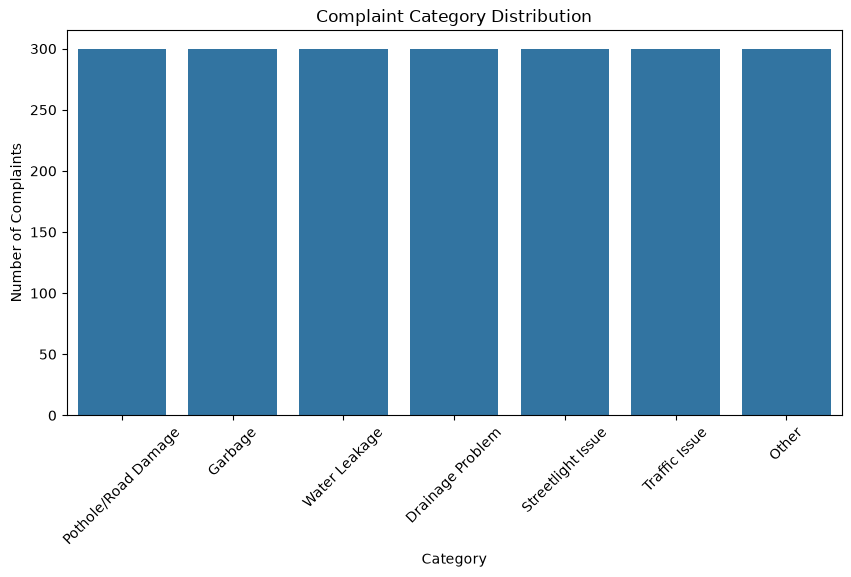

In [8]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.xticks(rotation=45)
plt.xlabel("Category")
plt.ylabel("Number of Complaints")
plt.title("Complaint Category Distribution")

plt.show()

In [9]:
# Number of words in each complaint

df["text_length"] = df["text"].apply(
    lambda x: len(str(x).split())
)

df.head()

,text,category,text_length
0,Please report: pothole near my house; causing ...,Pothole/Road Damage,15
1,"big pothole near my house, since last week; ca...",Pothole/Road Damage,14
2,Urgent: near my house road broken hai. causing...,Pothole/Road Damage,16
3,gaddha on road near my house. causing accident...,Pothole/Road Damage,12
4,"Need help, rasta kharab aahe near my house -- ...",Pothole/Road Damage,18


In [10]:
print("Average words per complaint:",
      df["text_length"].mean())

print("Maximum words:",
      df["text_length"].max())

print("Minimum words:",
      df["text_length"].min())

Average words per complaint: 18.314285714285713
Maximum words: 25
Minimum words: 10


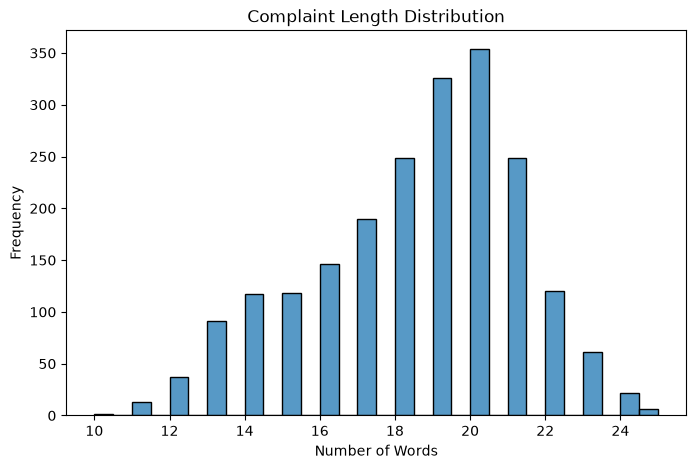

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["text_length"],
    bins=30
)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Complaint Length Distribution")

plt.show()

In [12]:
from collections import Counter

all_words = " ".join(df["text"]).lower().split()

word_frequency = Counter(all_words)

word_frequency.most_common(30)

[('since', 1750),
 ('last', 1750),
 ('please', 1200),
 ('week.', 1050),
 ('the', 940),
 ('is', 750),
 ('road', 701),
 ('near', 700),
 ('there', 650),
 ('water', 620),
 ('are', 600),
 ('this', 570),
 ('on', 570),
 ('should', 480),
 ('take', 480),
 ('at', 430),
 ('solve', 420),
 ('it', 420),
 ('municipality', 420),
 ('has', 380),
 ('send', 360),
 ('week;', 350),
 ('hai.', 350),
 ('--', 350),
 ('week,', 350),
 ('been', 350),
 ('unsafe', 300),
 ('to', 290),
 ('my', 280),
 ('outside', 280)]

In [13]:
from collections import Counter

# Combine all complaint text
all_text = " ".join(df["text"]).lower()

# Split into words
all_words = all_text.split()

# Count frequency
word_frequency = Counter(all_words)

# Show most common words
word_frequency.most_common(30)

[('since', 1750),
 ('last', 1750),
 ('please', 1200),
 ('week.', 1050),
 ('the', 940),
 ('is', 750),
 ('road', 701),
 ('near', 700),
 ('there', 650),
 ('water', 620),
 ('are', 600),
 ('this', 570),
 ('on', 570),
 ('should', 480),
 ('take', 480),
 ('at', 430),
 ('solve', 420),
 ('it', 420),
 ('municipality', 420),
 ('has', 380),
 ('send', 360),
 ('week;', 350),
 ('hai.', 350),
 ('--', 350),
 ('week,', 350),
 ('been', 350),
 ('unsafe', 300),
 ('to', 290),
 ('my', 280),
 ('outside', 280)]

In [14]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in all_words
    if word not in stop_words
]

Counter(filtered_words).most_common(30)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/rushikeshmarotraojoshi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[('since', 1750),
 ('last', 1750),
 ('please', 1200),
 ('week.', 1050),
 ('road', 701),
 ('near', 700),
 ('water', 620),
 ('take', 480),
 ('solve', 420),
 ('municipality', 420),
 ('send', 360),
 ('week;', 350),
 ('hai.', 350),
 ('--', 350),
 ('week,', 350),
 ('unsafe', 300),
 ('outside', 280),
 ('need', 240),
 ('street', 240),
 ('action.', 225),
 ('light', 220),
 ('report:', 210),
 ('issue.', 210),
 ('urgent:', 210),
 ('help,', 210),
 ('kripya', 210),
 ('dekhiye,', 210),
 ('check,', 210),
 ('dirty', 210),
 ('clean', 210)]

In [15]:
for category in df["category"].unique():

    text = " ".join(
        df[df["category"] == category]["text"]
    ).lower()

    words = Counter(text.split())

    print("\nCategory:", category)
    print(words.most_common(10))


Category: Pothole/Road Damage
[('since', 250), ('last', 250), ('road', 238), ('please', 180), ('causing', 150), ('week.', 150), ('vehicles', 150), ('are', 150), ('on', 120), ('it', 110)]

Category: Garbage
[('since', 250), ('last', 250), ('there', 200), ('please', 180), ('is', 180), ('garbage', 150), ('dogs', 150), ('are', 150), ('tearing', 150), ('week.', 150)]

Category: Water Leakage
[('water', 450), ('is', 300), ('since', 250), ('last', 250), ('the', 190), ('road', 178), ('clean', 150), ('week.', 150), ('always', 150), ('please', 120)]

Category: Drainage Problem
[('since', 250), ('last', 250), ('there', 200), ('the', 190), ('please', 180), ('is', 180), ('dirty', 180), ('water', 170), ('comes', 150), ('onto', 150)]

Category: Streetlight Issue
[('since', 250), ('last', 250), ('street', 240), ('light', 190), ('at', 190), ('please', 180), ('to', 170), ('the', 160), ('becomes', 150), ('unsafe', 150)]

Category: Traffic Issue
[('since', 250), ('last', 250), ('please', 180), ('traffic'

In [16]:
import re

def clean_text(text):

    # Convert to string
    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters but keep alphabets and spaces
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    # Strip spaces from beginning/end
    text = text.strip()

    return text

In [17]:
sample = "URGENT!!! Street LIGHT not working 😡 near my house."

clean_text(sample)

'urgent street light not working near my house'

In [18]:
df["clean_text"] = df["text"].apply(clean_text)

df.head()

,text,category,text_length,clean_text
0,Please report: pothole near my house; causing ...,Pothole/Road Damage,15,please report pothole near my house causing ac...
1,"big pothole near my house, since last week; ca...",Pothole/Road Damage,14,big pothole near my house since last week caus...
2,Urgent: near my house road broken hai. causing...,Pothole/Road Damage,16,urgent near my house road broken hai causing a...
3,gaddha on road near my house. causing accident...,Pothole/Road Damage,12,gaddha on road near my house causing accidents...
4,"Need help, rasta kharab aahe near my house -- ...",Pothole/Road Damage,18,need help rasta kharab aahe near my house caus...


In [19]:
for i in range(5):

    print("Original:")
    print(df["text"][i])

    print("\nCleaned:")
    print(df["clean_text"][i])

    print("-"*50)

Original:
Please report: pothole near my house; causing accidents since last week. please solve this issue.

Cleaned:
please report pothole near my house causing accidents since last week please solve this issue
--------------------------------------------------
Original:
big pothole near my house, since last week; causing accidents. please solve this issue!

Cleaned:
big pothole near my house since last week causing accidents please solve this issue
--------------------------------------------------
Original:
Urgent: near my house road broken hai. causing accidents, since last week. please solve this issue.

Cleaned:
urgent near my house road broken hai causing accidents since last week please solve this issue
--------------------------------------------------
Original:
gaddha on road near my house. causing accidents. please solve this issue

Cleaned:
gaddha on road near my house causing accidents please solve this issue
--------------------------------------------------
Original:
Nee

In [20]:
df["category"].unique()

<ArrowStringArray>
['Pothole/Road Damage',             'Garbage',       'Water Leakage',
    'Drainage Problem',   'Streetlight Issue',       'Traffic Issue',
               'Other']
Length: 7, dtype: str

In [21]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["category"])

df.head()

,text,category,text_length,clean_text,label
0,Please report: pothole near my house; causing ...,Pothole/Road Damage,15,please report pothole near my house causing ac...,3
1,"big pothole near my house, since last week; ca...",Pothole/Road Damage,14,big pothole near my house since last week caus...,3
2,Urgent: near my house road broken hai. causing...,Pothole/Road Damage,16,urgent near my house road broken hai causing a...,3
3,gaddha on road near my house. causing accident...,Pothole/Road Damage,12,gaddha on road near my house causing accidents...,3
4,"Need help, rasta kharab aahe near my house -- ...",Pothole/Road Damage,18,need help rasta kharab aahe near my house caus...,3


In [22]:
label_mapping = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
)

label_mapping


{'Drainage Problem': np.int64(0),
 'Garbage': np.int64(1),
 'Other': np.int64(2),
 'Pothole/Road Damage': np.int64(3),
 'Streetlight Issue': np.int64(4),
 'Traffic Issue': np.int64(5),
 'Water Leakage': np.int64(6)}

In [23]:
id2label = {
    value: key
    for key, value in label_mapping.items()
}

id2label

{np.int64(0): 'Drainage Problem',
 np.int64(1): 'Garbage',
 np.int64(2): 'Other',
 np.int64(3): 'Pothole/Road Damage',
 np.int64(4): 'Streetlight Issue',
 np.int64(5): 'Traffic Issue',
 np.int64(6): 'Water Leakage'}

In [24]:
from sklearn.model_selection import train_test_split
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

In [25]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

In [26]:
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 1470
Validation samples: 315
Testing samples: 315


In [27]:
print("Training distribution:")
print(train_df["category"].value_counts())

print("\nValidation distribution:")
print(val_df["category"].value_counts())

print("\nTesting distribution:")
print(test_df["category"].value_counts())

Training distribution:
category
Other                  210
Water Leakage          210
Traffic Issue          210
Pothole/Road Damage    210
Drainage Problem       210
Streetlight Issue      210
Garbage                210
Name: count, dtype: int64

Validation distribution:
category
Streetlight Issue      45
Other                  45
Pothole/Road Damage    45
Garbage                45
Traffic Issue          45
Water Leakage          45
Drainage Problem       45
Name: count, dtype: int64

Testing distribution:
category
Drainage Problem       45
Traffic Issue          45
Other                  45
Pothole/Road Damage    45
Garbage                45
Streetlight Issue      45
Water Leakage          45
Name: count, dtype: int64


In [28]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch



In [29]:
model_name = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully ✅")

Tokenizer loaded successfully ✅


In [30]:
sample_text = train_df["clean_text"].iloc[0]

print(sample_text)

tokens = tokenizer(
    sample_text
)

tokens

public bench damaged on road to station unsafe for children please inspect this urgently


{'input_ids': [0, 3835, 1585, 206, 82649, 71, 98, 33816, 47, 29398, 51, 115840, 100, 20020, 22936, 134071, 903, 89014, 538, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [31]:
token_ids = tokens["input_ids"]

decoded = tokenizer.decode(token_ids)

print(decoded)

<s> public bench damaged on road to station unsafe for children please inspect this urgently</s>


In [32]:
from torch.utils.data import Dataset, DataLoader

In [33]:
class CivicComplaintDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=128):

        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length


    def __len__(self):

        return len(self.texts)


    def __getitem__(self, index):

        text = str(self.texts[index])
        label = self.labels[index]


        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )


        return {
            "input_ids": encoding["input_ids"].squeeze(),
            "attention_mask": encoding["attention_mask"].squeeze(),
            "labels": torch.tensor(label, dtype=torch.long)
        }

In [34]:
train_dataset = CivicComplaintDataset(
    train_df["clean_text"].values,
    train_df["label"].values,
    tokenizer
)


val_dataset = CivicComplaintDataset(
    val_df["clean_text"].values,
    val_df["label"].values,
    tokenizer
)


test_dataset = CivicComplaintDataset(
    test_df["clean_text"].values,
    test_df["label"].values,
    tokenizer
)

In [35]:
sample = train_dataset[0]

sample

{'input_ids': tensor([     0,   3835,   1585,    206,  82649,     71,     98,  33816,     47,
          29398,     51, 115840,    100,  20020,  22936, 134071,    903,  89014,
            538,      2,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1

In [36]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=16
)


test_loader = DataLoader(
    test_dataset,
    batch_size=16
)

In [37]:
from transformers import AutoModelForSequenceClassification


In [38]:
model_name = "xlm-roberta-base"

num_classes = len(label_mapping)

print("Number of classes:", num_classes)

Number of classes: 7


In [39]:
id2label = {
    int(key): value
    for key, value in id2label.items()
}

id2label

{0: 'Drainage Problem',
 1: 'Garbage',
 2: 'Other',
 3: 'Pothole/Road Damage',
 4: 'Streetlight Issue',
 5: 'Traffic Issue',
 6: 'Water Leakage'}

In [40]:
label2id = {
    key: int(value)
    for key, value in label_mapping.items()
}

label2id

{'Drainage Problem': 0,
 'Garbage': 1,
 'Other': 2,
 'Pothole/Road Damage': 3,
 'Streetlight Issue': 4,
 'Traffic Issue': 5,
 'Water Leakage': 6}